# 03 · MRI Voxels → Physical Histology Blocks

Uses `mri_utils.py` (`mu`). A histology lab cuts physical tissue blocks on a microtome, not voxels. This notebook maps a 3D lesion mask onto the right block and section numbers, using each block's cutting-plane vector `manifest["blocks"][...]["krow"] = [a, b, c, d]`.

In [ ]:
import sys
from pathlib import Path
if ".." not in sys.path:
    sys.path.append("..")

DATA_DIR = Path("data") if Path("data").is_dir() else Path("../data") if Path("../data").is_dir() else Path(".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

import mri_utils as mu

manifest = json.load(open(DATA_DIR / "manifest.json"))
pair_11 = mu.load_diffusion_pair(str(DATA_DIR / "iv11_DWI.nii.gz"), str(DATA_DIR / "iv11_ADC.nii.gz"))
masks_11 = mu.restricted_diffusion_lesion(pair_11, dwi_threshold=150.0, adc_max=750.0, return_all=True)
iv11 = pair_11.dwi


## 3.1 Voxels → Block & Section

$$\text{slice\_coord} = a \cdot i + b \cdot j + c \cdot k + d$$

`mu.map_voxel_to_histology_section(mask, manifest)` solves this for every lesion voxel, returning which block and section number each one falls on.

In [21]:
section_df = mu.map_voxel_to_histology_section(masks_11["core"], manifest)

section_summary = section_df.groupby("block_id").agg(
    n_voxels=("i", "size"),
    section_min=("section", "min"),
    section_max=("section", "max"),
    global_id_min=("global_section_id", "min"),
    global_id_max=("global_section_id", "max"),
    in_range_pct=("in_range", "mean"),
).reset_index()
display(section_summary)

,block_id,n_voxels,section_min,section_max,global_id_min,global_id_max,in_range_pct
0,217,76133,94,1805,4438,6149,0.99803
1,218,27701,202,1955,6337,8090,1.00000
2,313,227530,24,1842,2596,4414,1.00000
3,314,58384,145,1156,363,1374,1.00000
4,315,98734,147,986,1665,2504,1.00000


### 3.2 Which Block to Pull

- **Block 313** (left medial) carries most of the core: 46.6%, sections ~24–1842.
- Secondary overlap: blocks 314, 315.
- **Caveat**: ADC coverage only exists for left-hemisphere blocks (313/314/315); any voxels mapped to right blocks (217/218) are likely threshold noise, not real right-sided injury.

## 3.3 MRI Along the Cutting Plane

`mu.extract_block_plane_from_mri(mri, manifest, block_id, section)` reslices the MRI along a block's true oblique cutting angle — a sanity check that the geometry is behaving as expected, for section 1019 on block 313.

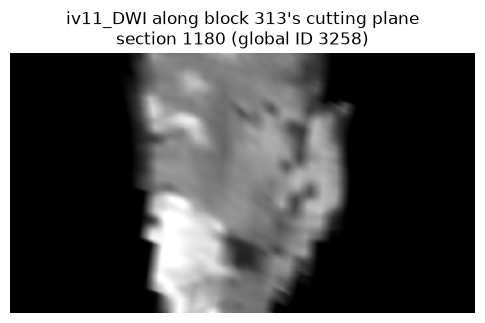

In [22]:
block_id = 313
in_block = section_df[section_df["block_id"] == block_id]
target_section = int(in_block["section"].median())

plane = mu.extract_block_plane_from_mri(iv11, manifest, block_id=block_id, section=target_section)

plt.figure(figsize=(6, 8))
plt.imshow(plane["image"], cmap="gray", origin="lower",
          aspect=plane["spacing_mm"][1] / plane["spacing_mm"][0])
plt.title(f"iv11_DWI along block {block_id}'s cutting plane\n"
         f"section {plane['section']} (global ID {plane['global_section_id']})")
plt.axis("off")
plt.show()

### 3.4 A Boundary to Remember

`krow` only resolves **which section** a voxel falls on (out-of-plane). It does **not** give 2D in-plane pixel registration between a histology image and the MRI slice — don't assume pixel (x, y) means the same thing in both.

**Next**: Notebook 04 moves into the histology side — loading the real ROI image stack and its digital-pathology annotations.